<a href="https://colab.research.google.com/github/thejuthejaskg-lab/Machine_Learning/blob/main/diabetes_decision_tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,f1_score,precision_score,recall_score

In [ ]:
# 2. Load dataset file_path = "/content/CAR DETAILS FROM CAR DEKHO.excel"
df = pd.read_excel("/content/diabetesxl.xlsx")
print("--- Dataset Head ---")
print(df.head(10))

--- Dataset Head ---
   preg  plas  pres  skin  insu  mass   pedi  age            class
0     6   148    72    35     0  33.6  0.627   50  tested_positive
1     1    85    66    29     0  26.6  0.351   31  tested_negative
2     8   183    64     0     0  23.3  0.672   32  tested_positive
3     1    89    66    23    94  28.1  0.167   21  tested_negative
4     0   137    40    35   168  43.1  2.288   33  tested_positive
5     5   116    74     0     0  25.6  0.201   30  tested_negative
6     3    78    50    32    88  31.0  0.248   26  tested_positive
7    10   115     0     0     0  35.3  0.134   29  tested_negative
8     2   197    70    45   543  30.5  0.158   53  tested_positive
9     8   125    96     0     0   0.0  0.232   54  tested_positive


In [ ]:
# 3. Find null values and drop
print("--- Null Values Before Drop ---")
print(df.isnull().sum())
df = df.dropna()
print("\n--- Null Values After Drop ---")
print(df.isnull().sum())
print()

--- Null Values Before Drop ---
preg     0
plas     0
pres     0
skin     0
insu     0
mass     0
pedi     0
age      0
class    0
dtype: int64

--- Null Values After Drop ---
preg     0
plas     0
pres     0
skin     0
insu     0
mass     0
pedi     0
age      0
class    0
dtype: int64



In [ ]:
# 4. Check duplicates and drop
print(f"Duplicates before: {df.duplicated().sum()}")
df = df.drop_duplicates()
print(f"Duplicates after:  {df.duplicated().sum()}")
print()

Duplicates before: 0
Duplicates after:  0



In [ ]:
x = df[['age','mass','insu','plas']]
y = df['class']
x = df[['age' , 'mass' , 'insu' , 'plas']]
y = df['class']
print("--- Features X (head) ---")
print(x.head(10))
print("\n--- Target Y (head) ---")
print(y.head(10))
print()

--- Features X (head) ---
   age  mass  insu  plas
0   50  33.6     0   148
1   31  26.6     0    85
2   32  23.3     0   183
3   21  28.1    94    89
4   33  43.1   168   137
5   30  25.6     0   116
6   26  31.0    88    78
7   29  35.3     0   115
8   53  30.5   543   197
9   54   0.0     0   125

--- Target Y (head) ---
0    tested_positive
1    tested_negative
2    tested_positive
3    tested_negative
4    tested_positive
5    tested_negative
6    tested_positive
7    tested_negative
8    tested_positive
9    tested_positive
Name: class, dtype: object



In [ ]:
# 7. Split Train Test (20%)
xtrain, xtest, ytrain, ytest = train_test_split( x, y, test_size=0.2, random_state=42 )
print(f"Xtrain shape: {xtrain.shape}")
print(f"Xtest shape:  {xtest.shape}")
print()

Xtrain shape: (614, 4)
Xtest shape:  (154, 4)



In [ ]:
decision = DecisionTreeClassifier()
decision.fit(xtrain,ytrain)

DecisionTreeClassifier()

In [ ]:
y_pred = decision.predict(xtest)
result = pd.DataFrame({
    'Actual': ytest,
    'Predicted': y_pred
})
print(result)


              Actual        Predicted
668  tested_negative  tested_positive
324  tested_negative  tested_positive
624  tested_negative  tested_negative
690  tested_negative  tested_negative
473  tested_negative  tested_negative
..               ...              ...
355  tested_positive  tested_negative
534  tested_negative  tested_negative
344  tested_negative  tested_positive
296  tested_positive  tested_negative
462  tested_negative  tested_negative

[154 rows x 2 columns]


In [ ]:
age = int(input("enter the age:"))
mass = int(input("enter the mass:"))
insulin = int(input("enter the insulin level:"))
plasma = int(input("enter the plasma level:"))
pred = decision.predict([[age,mass,insulin,plasma]])
print(pred)

enter the age:34
enter the mass:3
enter the insulin level:3
enter the plasma level:3
['tested_positive']


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


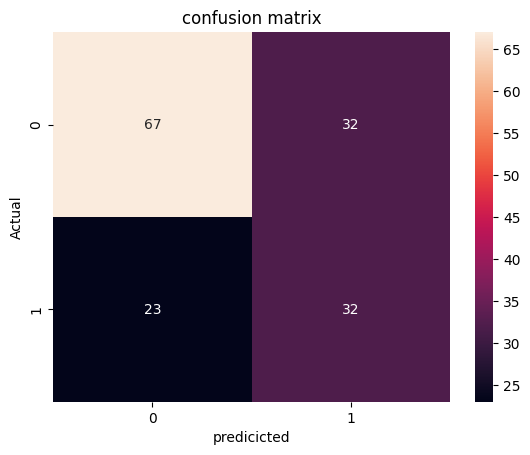

In [ ]:
import matplotlib.pyplot as plt
cm = confusion_matrix(ytest,y_pred)
sns.heatmap(cm,annot=True)
plt.xlabel("predicicted")
plt.ylabel("Actual")
plt.title("confusion matrix")
plt.show()


In [ ]:
from sklearn.tree import plot_tree

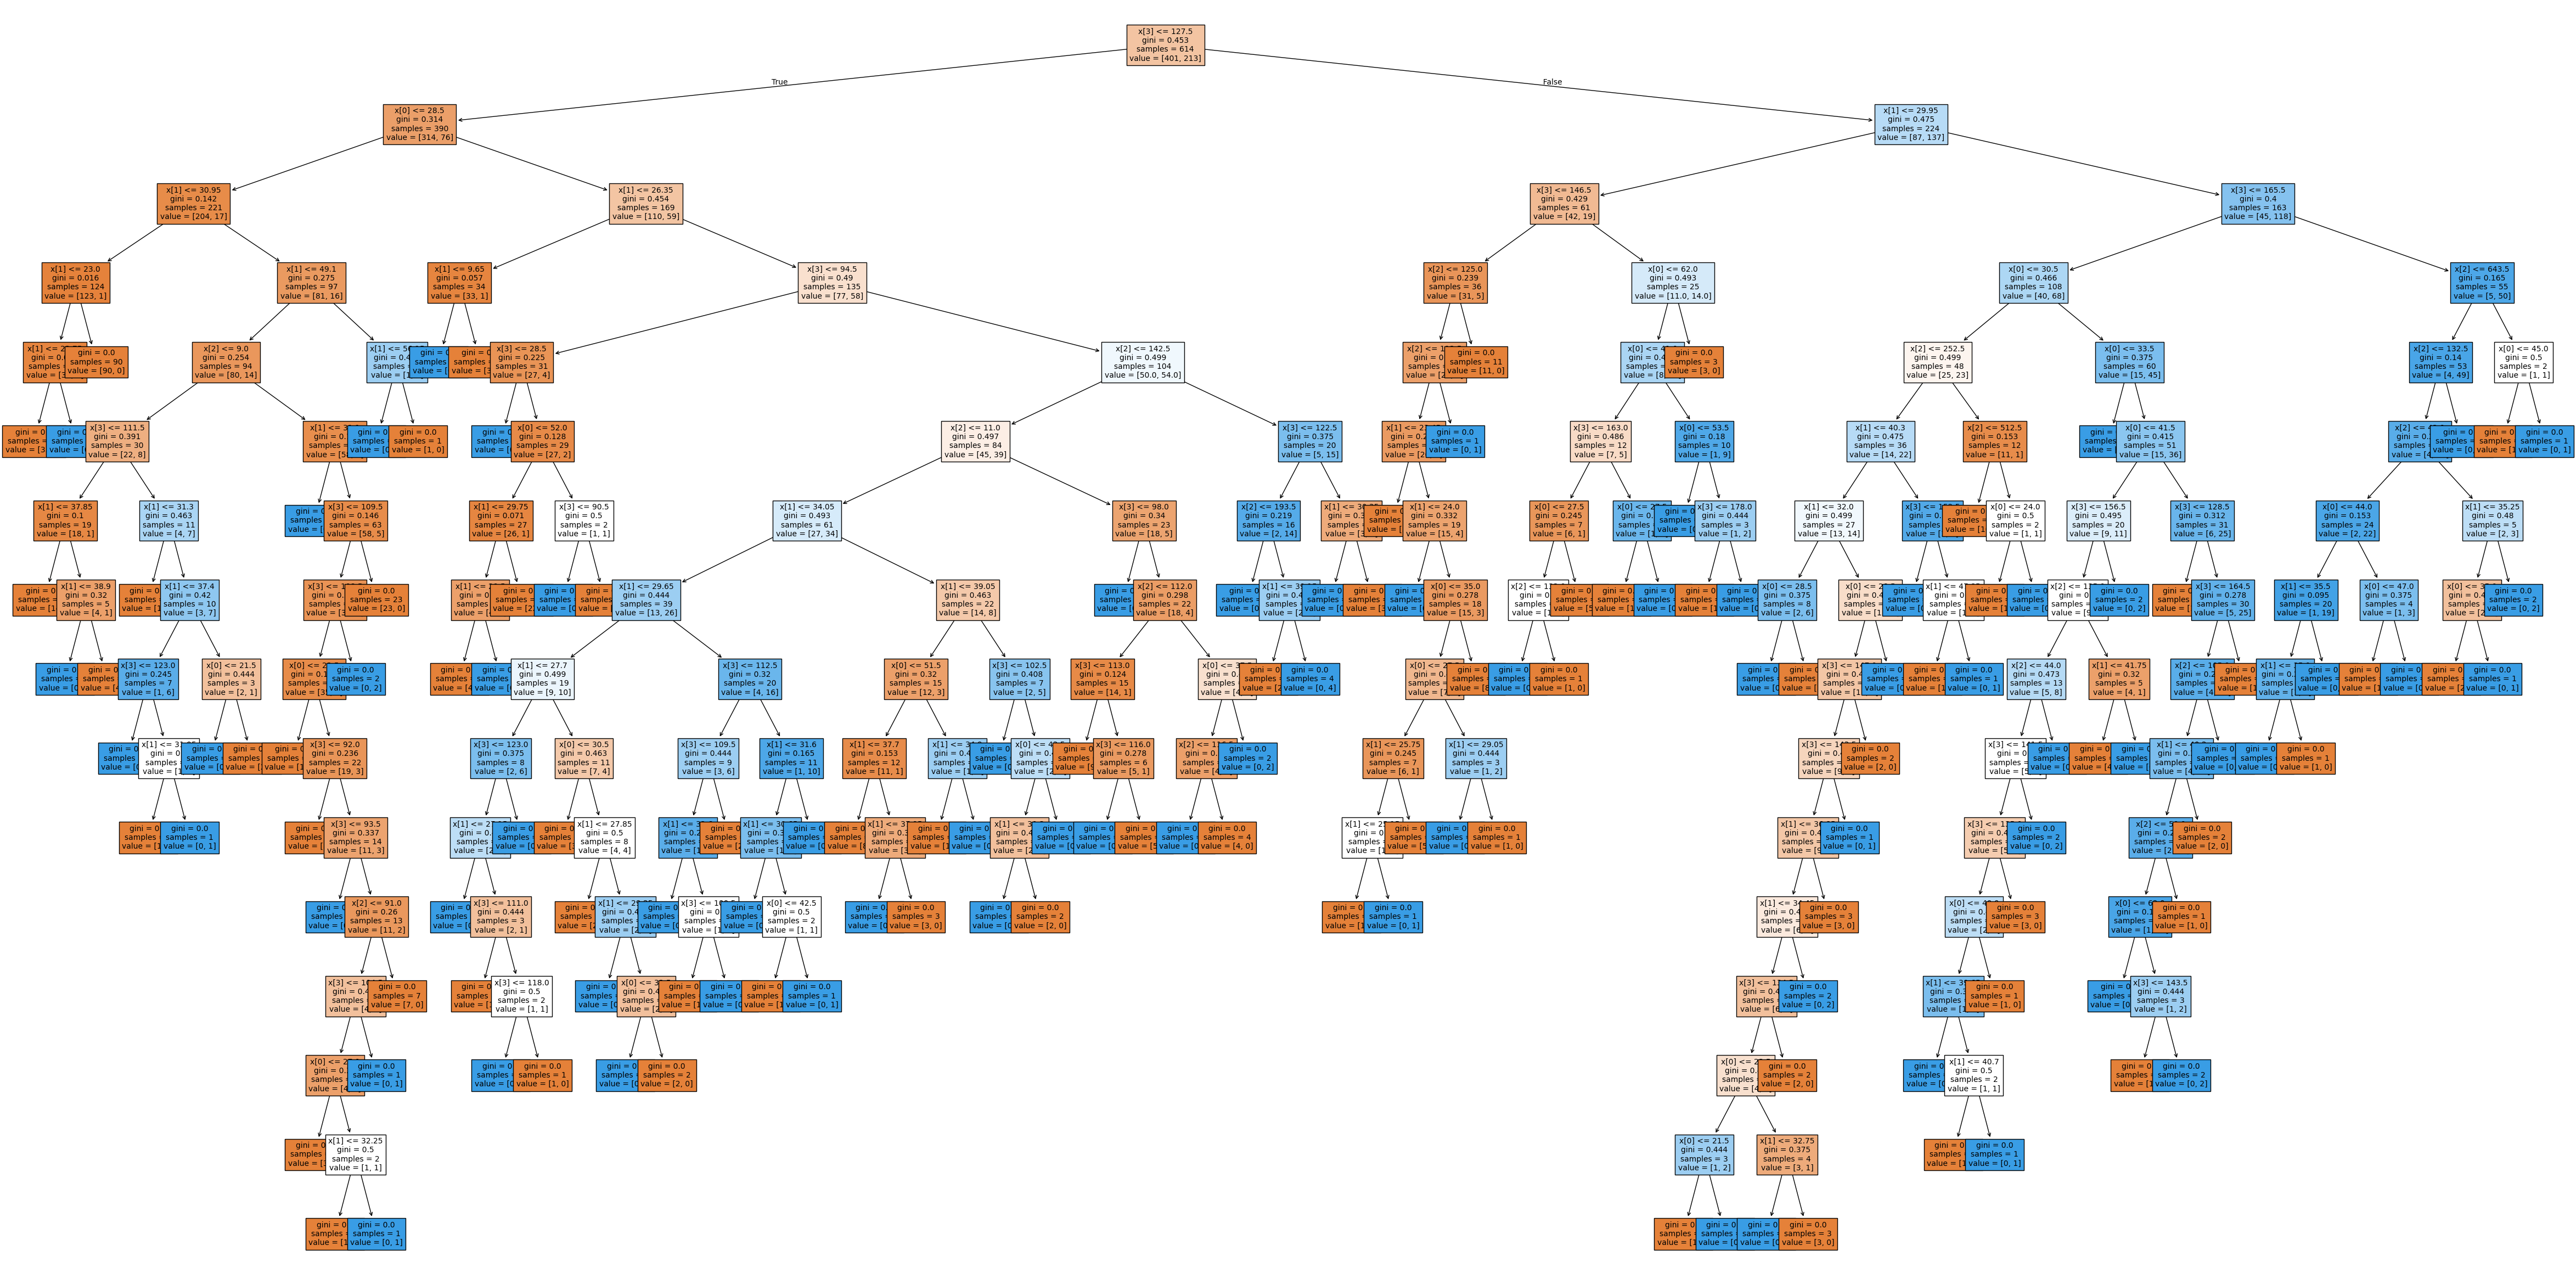

In [ ]:
plt.figure(figsize=(60, 30))
plot_tree(decision, fontsize=10, filled=True)
plt.savefig("decisiontree.pdf")
plt.show()